# 04 — Baseline comparison, model selection, and final testing

Run after the three model notebooks. All selection and test functions are visible here. Defaults display the existing frozen results. Set `RUN_SELECTION` only for a new experiment after all three models are trained; set `RUN_FINAL_TEST` once after selection. Never reselect after viewing the test. The v2 model was already selected and tested.

## 1 — Paths, target, weights, and predictor allowlist

In [1]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = globals().get('ROOT')
if ROOT is None:
    ROOT = next((p for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 for p in [base, base / 'components/habitat_risk']
                 if (p / 'configs/hri.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter inside the project repository.')
NOTEBOOK_DIR = ROOT / 'notebooks/hri/HRI_t_plus_1'
# A completed experiment is frozen. Use a new name for further development.
DATA_VERSION = 'hri_t_plus_1_v2'
EXPERIMENT_NAME = 'hri_t_plus_1_v2'

DATA = ROOT / "data/processed/hri" / DATA_VERSION
ARTIFACTS = ROOT / "artifacts/hri" / EXPERIMENT_NAME
KEY = ["cell_id", "reference_year"]
CORE = ["forest_amount_risk", "recent_loss_risk", "cumulative_loss_risk", "fragmentation_risk"]
CONFIG = json.loads((ROOT / "configs/hri.json").read_text())
WEIGHTS = CONFIG["weights"]
THRESHOLDS = CONFIG["risk_class_thresholds"]
RAW_FEATURES = [
    "forest__remaining_baseline_forest_proportion", "forest__annual_loss_fraction_of_baseline",
    "forest__cumulative_prior_loss_fraction_of_baseline", "forest__previous_3yr_loss_fraction_of_baseline",
    "forest__previous_5yr_loss_fraction_of_baseline", "forest__baseline_canopy_percent",
    "fragmentation__cell_patch_count", "fragmentation__mean_cell_patch_ha",
    "fragmentation__edge_m_per_land_ha", "terrain__mean_elevation_m",
    "terrain__mean_slope_degrees", "climate__annual_mean_temperature_c",
    "climate__annual_precipitation_mm",
]
FEATURES = RAW_FEATURES + CORE + [
    "hri_score_t", "hri_change_previous_year", "annual_loss_fraction_lag1",
    "annual_loss_fraction_lag2", "forest_proportion_change_previous_year",
    "edge_density_change_previous_year", "known_recent_loss_risk_t1",
    "known_cumulative_loss_risk_t1", "transition_hri_baseline",
]
TARGET = "target_hri_score_t1"




def risk_class(scores):
    return pd.cut(pd.Series(scores), [-np.inf, THRESHOLDS["low_upper"], THRESHOLDS["moderate_upper"], np.inf],
                  labels=["Low", "Moderate", "High"], right=True).astype("string")

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


In [2]:
import sys
import types
import time
import warnings
import joblib
import sklearn
from IPython.display import display, Image, Markdown
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    balanced_accuracy_score, f1_score, classification_report, confusion_matrix)
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
LABELS = ['Low', 'Moderate', 'High']
MODELS = ['ridge', 'random_forest', 'xgboost']


## 2 — Forecast estimators: direct scores or corrections to a known baseline

In [3]:
class HriForecaster(RegressorMixin, BaseEstimator):
    """A fold-fitted estimator of score or residual relative to an as-of-t baseline."""
    def __init__(self, estimator=None, mode="transition"):
        self.estimator = estimator
        self.mode = mode

    def offset(self, X):
        if self.mode == "direct":
            return np.zeros(len(X))
        return X["hri_score_t" if self.mode == "persistence" else "transition_hri_baseline"].to_numpy()

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X[FEATURES], np.asarray(y) - self.offset(X))
        self.n_features_in_ = len(FEATURES)
        self.feature_names_in_ = np.array(FEATURES, dtype=object)
        return self

    def predict(self, X):
        return np.clip(self.offset(X) + self.estimator_.predict(X[FEATURES]), 0, 100)

class ReferenceForecaster(RegressorMixin, BaseEstimator):
    def __init__(self, name="persistence"):
        self.name = name

    def fit(self, X, y):
        self.mean_ = float(np.mean(y))
        return self

    def predict(self, X):
        if self.name == "mean":
            return np.repeat(self.mean_, len(X))
        return X["hri_score_t" if self.name == "persistence" else "transition_hri_baseline"].to_numpy()

# Existing joblib models refer to training.HriForecaster.
# Register the visible notebook classes so those models remain loadable.
runtime = sys.modules.get('training') or types.ModuleType('training')
for estimator_class in [HriForecaster, ReferenceForecaster]:
    estimator_class.__module__ = 'training'
    setattr(runtime, estimator_class.__name__, estimator_class)
sys.modules['training'] = runtime


## 3 — Verify the dataset and define forward/block cross-validation

In [4]:
def load_data():
    frame = pd.read_csv(DATA / "forecast_dataset.csv")
    audit = json.loads((DATA / "dataset_audit.json").read_text())
    if sha256(DATA / "forecast_dataset.csv") != audit["dataset_sha256"]:
        raise ValueError("Dataset differs from its frozen audit")
    if audit["weights"] != WEIGHTS or audit["thresholds"] != THRESHOLDS:
        raise ValueError("HRI configuration changed since dataset construction")
    if frame[[TARGET, "hri_score_t", "transition_hri_baseline"]].isna().any().any():
        raise ValueError("Missing target/baseline")
    if not (frame.target_year_t1 == frame.reference_year + 1).all():
        raise ValueError("Invalid forecast horizon")
    if frame.groupby("spatial_block").spatial_partition.nunique().max() != 1:
        raise ValueError("Block leakage")
    return frame

def views(frame, phase="validation"):
    """Separate later years, unseen 25km blocks, and their intersection."""
    return {
        "temporal": frame.loc[frame.spatial_partition.eq("train") & frame.time_partition.eq(phase)],
        "spatial": frame.loc[frame.spatial_partition.eq(phase) & frame.time_partition.eq("train")],
        "joint": frame.loc[frame.spatial_partition.eq(phase) & frame.time_partition.eq(phase)],
    }

def historical_train(frame):
    return frame.loc[frame.spatial_partition.eq("train") & frame.time_partition.eq("train")].reset_index(drop=True)

def blocked_forward_cv(train):
    """Validate in later years and held-out blocks within the training era."""
    blocks = np.array(sorted(train.spatial_block.unique()))
    np.random.default_rng(42).shuffle(blocks)
    cohorts = {b: i % 3 for i, b in enumerate(blocks)}
    folds, audit = [], []
    for k, year in enumerate([2017, 2018, 2019]):
        held_out = train.spatial_block.map(cohorts).eq(k)
        fit = np.flatnonzero((train.target_year_t1.lt(year) & ~held_out).to_numpy())
        assess = np.flatnonzero((train.target_year_t1.eq(year) & held_out).to_numpy())
        if not len(fit) or not len(assess):
            raise ValueError("Empty blocked forward fold")
        a, b = train.iloc[fit], train.iloc[assess]
        if a.target_year_t1.max() >= b.target_year_t1.min() or set(a.spatial_block) & set(b.spatial_block):
            raise ValueError("CV time/block leakage")
        folds.append((fit, assess))
        audit.append({"fold": k, "train_rows": len(a), "assessment_rows": len(b),
                      "last_training_target_year": int(a.target_year_t1.max()), "assessment_target_year": year,
                      "train_blocks": a.spatial_block.nunique(), "assessment_blocks": b.spatial_block.nunique(),
                      "time_overlap": False, "block_overlap": False})
    return folds, pd.DataFrame(audit)


In [5]:
frame = load_data()
train = historical_train(frame)
folds, fold_audit = blocked_forward_cv(train)
print('Training rows:', len(train), 'Features:', len(FEATURES))
display(fold_audit)


Training rows: 9075 Features: 26


,fold,train_rows,assessment_rows,last_training_target_year,assessment_target_year,train_blocks,assessment_blocks,time_overlap,block_overlap
0,0,2340,645,2016,2017,61,31,False,False
1,1,3597,616,2017,2018,61,31,False,False
2,2,5044,554,2018,2019,62,30,False,False


## 5 — Consistent regression, risk classes, and exports

In [6]:
def metrics(frame, pred):
    y = frame[TARGET].to_numpy()
    actual = risk_class(y).to_numpy()
    predicted = risk_class(pred).to_numpy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        balanced = balanced_accuracy_score(actual, predicted)
    high = actual == "High"
    return {"n": len(frame), "MAE": float(mean_absolute_error(y, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred))), "R2": float(r2_score(y, pred)),
            "change_R2": float(r2_score(y-frame.hri_score_t.to_numpy(), pred-frame.hri_score_t.to_numpy())),
            "balanced_accuracy": float(balanced), "macro_F1": float(f1_score(actual, predicted, labels=LABELS, average="macro", zero_division=0)),
            "high_risk_n": int(high.sum()), "high_risk_MAE": float(np.abs(y[high]-pred[high]).mean()) if high.any() else None}

def export_assessment(name, model, frame, label, dest):
    prediction = model.predict(frame[FEATURES])
    out = frame[["cell_id", "reference_year", "target_year_t1", "spatial_block", "hri_score_t", TARGET]].copy()
    out["prediction"] = prediction
    out["predicted_change"] = prediction - out.hri_score_t
    out["actual_change"] = out[TARGET] - out.hri_score_t
    out["residual"] = out[TARGET] - prediction
    actual, predicted = risk_class(out[TARGET]).to_numpy(), risk_class(prediction).to_numpy()
    out["observed_risk_class"] = actual
    out["predicted_risk_class"] = predicted
    out.to_csv(dest / f"{label}_predictions.csv", index=False)
    pd.DataFrame(classification_report(actual, predicted, labels=LABELS, output_dict=True, zero_division=0)).T.to_csv(dest / f"{label}_classification.csv")
    pd.DataFrame(confusion_matrix(actual, predicted, labels=LABELS), index=LABELS, columns=LABELS).to_csv(dest / f"{label}_confusion_matrix.csv")
    bands = out.assign(risk_class=actual, absolute_error=np.abs(out.residual))
    bands.groupby("risk_class").agg(n=(TARGET, "size"), MAE=("absolute_error", "mean"),
                                    mean_residual=("residual", "mean")).to_csv(dest / f"{label}_risk_band_errors.csv")
    by_year = [{"target_year": int(year), **metrics(frame.loc[mask], prediction[mask.to_numpy()])}
               for year in sorted(frame.target_year_t1.unique())
               for mask in [frame.target_year_t1.eq(year)]]
    pd.DataFrame(by_year).to_csv(dest / f"{label}_metrics_by_year.csv", index=False)
    return {"model": name, "assessment": label, **metrics(frame, prediction)}

def assert_not_tested():
    if (ARTIFACTS / "final_test_manifest.json").exists():
        raise FileExistsError("This experiment has already been tested. Preserve it and create a new version for further research.")


## 6 — Baselines, validation selection, and learning history

In [7]:
def plot_diagnostics(model, frame, dest, label):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    y, pred = frame[TARGET].to_numpy(), model.predict(frame[FEATURES])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(y, pred, alpha=.3, s=6)
    axes[0].plot([0, 100], [0, 100], "k--")
    axes[0].set(xlabel="Observed HRI(t+1)", ylabel="Predicted HRI(t+1)", title=label)
    axes[1].scatter(pred, y-pred, alpha=.3, s=6)
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Prediction", ylabel="Observed minus predicted", title="Residuals")
    fig.tight_layout()
    fig.savefig(dest / f"{label}_diagnostics.png", dpi=180)
    plt.close(fig)


In [8]:
def select_model():
    assert_not_tested()
    frame = load_data()
    train = historical_train(frame)
    all_rows, models = [], {}
    for name in MODELS:
        metadata = json.loads((ARTIFACTS / name / "training_metadata.json").read_text())
        if metadata["dataset_sha256"] != sha256(DATA / "forecast_dataset.csv"):
            raise ValueError("Model was fitted to another dataset")
        model = joblib.load(ARTIFACTS / name / "model.joblib")
        models[name] = model
        rows = [export_assessment(name, model, train, "train", ARTIFACTS / name)]
        rows += [export_assessment(name, model, f, f"validation_{key}", ARTIFACTS / name)
                 for key, f in views(frame).items()]
        table = pd.DataFrame(rows)
        table.to_csv(ARTIFACTS / name / "metrics.csv", index=False)
        table["cv_MAE"] = metadata["cv_MAE"]
        all_rows += table.to_dict("records")
    cv, _ = blocked_forward_cv(train)
    for name in ["mean", "persistence", "transition"]:
        model = ReferenceForecaster(name).fit(train[FEATURES], train[TARGET])
        models[name] = model
        dest = ARTIFACTS / name
        dest.mkdir(exist_ok=True)
        cv_mae = np.mean([mean_absolute_error(train.iloc[b][TARGET],
                    ReferenceForecaster(name).fit(train.iloc[a][FEATURES], train.iloc[a][TARGET]).predict(train.iloc[b][FEATURES])) for a, b in cv])
        rows = [export_assessment(name, model, train, "train", dest)]
        rows += [export_assessment(name, model, f, f"validation_{k}", dest) for k, f in views(frame).items()]
        for row in rows:
            row["cv_MAE"] = float(cv_mae)
        all_rows += rows
    comparison = pd.DataFrame(all_rows)
    comparison.to_csv(ARTIFACTS / "all_validation_metrics.csv", index=False)
    ranking = comparison.loc[comparison.assessment.eq("validation_joint")].sort_values(["MAE", "cv_MAE"])
    ranking.to_csv(ARTIFACTS / "model_comparison.csv", index=False)
    winner = ranking.iloc[0]["model"]
    selected = models[winner]
    joblib.dump(selected, ARTIFACTS / "selected_model.joblib")
    selection = {"model": winner, "criterion": "Lowest MAE on unseen-block AND later-year validation; baselines eligible",
                 "joint_validation_MAE": float(ranking.iloc[0].MAE),
                 "dataset_sha256": sha256(DATA / "forecast_dataset.csv"),
                 "selected_model_sha256": sha256(ARTIFACTS / "selected_model.joblib"),
                 "features": FEATURES, "forecast_origin": "end of year t",
                 "source_sha256": {p.name: sha256(p) for p in NOTEBOOK_DIR.glob("*.ipynb")}}
    (ARTIFACTS / "selected_model.json").write_text(json.dumps(selection, indent=2))
    for key, f in views(frame).items():
        plot_diagnostics(selected, f, ARTIFACTS, "validation_"+key)
    # Learning history uses training-period rows and spatially held-out historical validation only.
    curve = []
    for end in [2016, 2017, 2018, 2019]:
        subset = train.loc[train.target_year_t1.le(end)]
        fitted = clone(selected).fit(subset[FEATURES], subset[TARGET])
        assessed = views(frame)["spatial"]
        assessed = assessed.loc[assessed.target_year_t1.eq(2019)]
        curve.append({"last_train_target_year": end, "n": len(subset),
                      "train_MAE": mean_absolute_error(subset[TARGET], fitted.predict(subset[FEATURES])),
                      "spatial_2019_MAE": mean_absolute_error(assessed[TARGET], fitted.predict(assessed[FEATURES]))})
    pd.DataFrame(curve).to_csv(ARTIFACTS / "learning_history.csv", index=False)
    print("Selection (test not used):", selection, flush=True)
    print(ranking.to_string(index=False), flush=True)
    return selected


## 7 — Select only for a new experiment

In [9]:
RUN_SELECTION = False
if RUN_SELECTION:
    selected_model = select_model()
else:
    selected_model = joblib.load(ARTIFACTS / 'selected_model.joblib')
    print('Selected model:', json.loads((ARTIFACTS / 'selected_model.json').read_text())['model'])
display(pd.read_csv(ARTIFACTS / 'model_comparison.csv'))
display(pd.read_csv(ARTIFACTS / 'all_validation_metrics.csv'))
display(pd.read_csv(ARTIFACTS / 'learning_history.csv'))


Selected model: ridge


,model,assessment,n,MAE,RMSE,R2,change_R2,balanced_accuracy,macro_F1,high_risk_n,high_risk_MAE,cv_MAE
0,ridge,validation_joint,620,0.057473,0.105469,0.999949,0.997561,0.997681,0.997681,26,0.075711,0.065493
1,random_forest,validation_joint,620,0.058175,0.107796,0.999946,0.997452,0.997268,0.997679,26,0.070918,0.061700
2,xgboost,validation_joint,620,0.060063,0.108451,0.999946,0.997421,0.997681,0.992074,26,0.073204,0.062181
3,transition,validation_joint,620,0.072806,0.144364,0.999904,0.995430,0.999048,0.998841,26,0.110951,0.083994
4,persistence,validation_joint,620,0.918840,2.138883,0.978892,-0.003092,0.972066,0.928753,26,3.324508,1.137543
5,mean,validation_joint,620,11.590842,14.733026,-0.001518,-46.593817,0.333333,0.240550,26,35.310281,11.111984


,model,assessment,n,MAE,RMSE,R2,change_R2,balanced_accuracy,macro_F1,high_risk_n,high_risk_MAE,cv_MAE
0,ridge,train,9075,0.069752,0.141268,0.999898,0.997087,0.997210,0.996232,331,0.110516,0.065493
1,ridge,validation_temporal,3630,0.054824,0.094027,0.999956,0.996962,0.996219,0.997348,142,0.082743,0.065493
2,ridge,validation_spatial,1550,0.070166,0.125669,0.999931,0.997709,0.999585,0.999546,71,0.150923,0.065493
3,ridge,validation_joint,620,0.057473,0.105469,0.999949,0.997561,0.997681,0.997681,26,0.075711,0.065493
4,random_forest,train,9075,0.060254,0.130314,0.999913,0.997521,0.997465,0.996998,331,0.094124,0.061700
5,random_forest,validation_temporal,3630,0.051956,0.093135,0.999957,0.997019,0.995421,0.996750,142,0.082352,0.061700
6,random_forest,validation_spatial,1550,0.064344,0.119316,0.999938,0.997935,0.999585,0.999546,71,0.123473,0.061700
7,random_forest,validation_joint,620,0.058175,0.107796,0.999946,0.997452,0.997268,0.997679,26,0.070918,0.061700
8,xgboost,train,9075,0.057031,0.115581,0.999932,0.998050,0.997861,0.997384,331,0.072811,0.062181
9,xgboost,validation_temporal,3630,0.053563,0.096097,0.999954,0.996826,0.995660,0.996949,142,0.096799,0.062181


,last_train_target_year,n,train_MAE,spatial_2019_MAE
0,2016,3630,0.074988,0.065162
1,2017,5445,0.075944,0.066002
2,2018,7260,0.073139,0.065451
3,2019,9075,0.069752,0.063277


## 8 — One-time test and block-bootstrap uncertainty code

In [10]:
def bootstrap_mae(frame, prediction, draws=300):
    """Resample geographic blocks, keeping repeated years/cells together."""
    table = pd.DataFrame({"block": frame.spatial_block.to_numpy(), "abs_error": np.abs(frame[TARGET].to_numpy()-prediction)})
    stats = table.groupby("block").abs_error.agg(["sum", "count"])
    rng = np.random.default_rng(42)
    indices = rng.integers(0, len(stats), size=(draws, len(stats)))
    values = stats["sum"].to_numpy()[indices].sum(axis=1) / stats["count"].to_numpy()[indices].sum(axis=1)
    return {"MAE_95CI_lower": float(np.quantile(values, .025)), "MAE_95CI_upper": float(np.quantile(values, .975)),
            "bootstrap_unit": "25km spatial block", "bootstrap_draws": draws}


In [11]:
def write_report(test_results, selection):
    """Write a standalone research handoff with limitations beside the scores."""
    validation = pd.read_csv(ARTIFACTS / "model_comparison.csv")
    fields = ["model", "MAE", "RMSE", "R2", "change_R2", "balanced_accuracy", "macro_F1", "high_risk_MAE"]
    def table(frame):
        rows = ["| " + " | ".join(fields) + " |", "|" + " --- |"*len(fields)]
        for _, row in frame.iterrows():
            rows.append("| " + " | ".join(str(row[k]) if k == "model" else f"{row[k]:.6f}" for k in fields) + " |")
        return "\n".join(rows)
    parts = ["# HRI(t+1) v2 results before SHAP", "",
             "Selected with joint validation MAE: **" + selection["model"] + "**. Test results were not used for selection.", "",
             "## Joint validation: later years and unseen 25 km blocks", "", table(validation)]
    for view in ["temporal", "spatial", "joint"]:
        table_rows = test_results.loc[test_results.assessment.str.startswith("test_"+view+"_")]
        parts += ["", "## Final test: "+view, "", table(table_rows)]
    parts += ["", "## Interpretation", "",
              "The target is the released constructed forest-oriented HRI with four equal 0.25 weights; numerical expert weights have not been obtained. Weights were not chosen to improve model scores.", "",
              "The transition baseline updates next-year recent/cumulative-loss index terms from already observed losses through t, then carries forward forest amount and fragmentation. Its strong performance reflects the target's construction and temporal persistence. Compare learned improvements over this baseline as well as over HRI persistence; high R² alone is not independent ecological validation.", "",
              "Training targets: 2015–2019; validation: 2020–2021; future test: 2022–2023. Geographic views use disjoint 25 km block cohorts. No spatial buffers were applied, so cross-boundary dependence may remain. The historic source data have been explored before and may contain retrospective product revisions.", "",
              "See final_test/test_metrics.csv for 95% MAE intervals from 300 spatial-block bootstrap draws, all_validation_metrics.csv for separate temporal/spatial/joint validation, each model's cv_results.csv for the forward-fold search, and learning_history.csv for historical diagnostics.", "",
              "The selected model remains fitted to the original training cohort. This experiment is now frozen; test results must not drive further tuning. Expert review of weights, classes, canopy applicability and grid resolution remains pending. SHAP and recommendation code were not executed for this new model."]
    (ARTIFACTS / "RESULTS.md").write_text("\n".join(parts)+"\n")


In [12]:
def final_test():
    assert_not_tested()
    selection = json.loads((ARTIFACTS / "selected_model.json").read_text())
    if selection["selected_model_sha256"] != sha256(ARTIFACTS / "selected_model.joblib"):
        raise ValueError("Selected model changed")
    frame = load_data()
    if selection["dataset_sha256"] != sha256(DATA / "forecast_dataset.csv"):
        raise ValueError("Dataset changed since selection")
    selected = joblib.load(ARTIFACTS / "selected_model.joblib")
    train = historical_train(frame)
    models = {selection["model"]: selected}
    for name in ["mean", "persistence", "transition"]:
        if name not in models:
            models[name] = ReferenceForecaster(name).fit(train[FEATURES], train[TARGET])
    dest = ARTIFACTS / "final_test"
    dest.mkdir(exist_ok=True)
    rows = []
    for key, assessed in views(frame, "test").items():
        for name, model in models.items():
            row = export_assessment(name, model, assessed, f"test_{key}_{name}", dest)
            row.update(bootstrap_mae(assessed, model.predict(assessed[FEATURES])))
            rows.append(row)
        plot_diagnostics(selected, assessed, dest, "test_"+key)
    pd.DataFrame(rows).to_csv(dest / "test_metrics.csv", index=False)
    (ARTIFACTS / "final_test_manifest.json").write_text(json.dumps({**selection,
        "status": "completed_once_do_not_tune_after_viewing", "test_target_years": [2022, 2023],
        "note": "Do not refit or select using these test scores; new research requires a new experiment version"}, indent=2))
    write_report(pd.DataFrame(rows), selection)
    print(pd.DataFrame(rows).to_string(index=False), flush=True)
    return pd.DataFrame(rows)


## 9 — Execute once or review the completed final tests

In [13]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    test_results = final_test()
else:
    saved_test = ARTIFACTS / 'final_test/test_metrics.csv'
    if saved_test.exists():
        display(pd.read_csv(saved_test))
        display(Markdown((ARTIFACTS / 'RESULTS.md').read_text()))
    else:
        print('No final test yet. Select the model before enabling RUN_FINAL_TEST.')


,model,assessment,n,MAE,RMSE,R2,change_R2,balanced_accuracy,macro_F1,high_risk_n,high_risk_MAE,MAE_95CI_lower,MAE_95CI_upper,bootstrap_unit,bootstrap_draws
0,ridge,test_temporal_ridge,3630,0.055240,0.090994,0.999960,0.997044,0.996115,0.994454,165,0.068070,0.049589,0.062935,25km spatial block,300
1,mean,test_temporal_mean,3630,11.314837,14.461170,-0.014984,-73.648805,0.333333,0.245431,165,35.140876,10.199890,12.358808,25km spatial block,300
2,persistence,test_temporal_persistence,3630,0.793635,1.689471,0.986147,-0.018867,0.930009,0.941631,165,2.814504,0.676773,0.922688,25km spatial block,300
3,transition,test_temporal_transition,3630,0.061825,0.118434,0.999932,0.994993,0.992994,0.995493,165,0.107346,0.051740,0.074441,25km spatial block,300
4,ridge,test_spatial_ridge,2000,0.072086,0.126207,0.999909,0.997496,0.997490,0.997391,75,0.090107,0.061712,0.082990,25km spatial block,300
5,mean,test_spatial_mean,2000,10.055503,13.330016,-0.018978,-26.934445,0.333333,0.252459,75,36.019857,7.853026,12.591365,25km spatial block,300
6,persistence,test_spatial_persistence,2000,1.357577,2.587826,0.961596,-0.052807,0.883599,0.887797,75,4.912864,1.063314,1.685287,25km spatial block,300
7,transition,test_spatial_transition,2000,0.103604,0.176599,0.999821,0.995097,0.992548,0.993539,75,0.073832,0.075669,0.133389,25km spatial block,300
8,ridge,test_joint_ridge,800,0.059819,0.086399,0.999968,0.998791,0.998333,0.998857,59,0.089942,0.050321,0.069850,25km spatial block,300
9,mean,test_joint_mean,800,11.495938,15.973605,-0.107911,-40.316194,0.333333,0.268954,59,39.119000,8.091141,15.289177,25km spatial block,300


# HRI(t+1) v2 results before SHAP

Selected with joint validation MAE: **ridge**. Test results were not used for selection.

## Joint validation: later years and unseen 25 km blocks

| model | MAE | RMSE | R2 | change_R2 | balanced_accuracy | macro_F1 | high_risk_MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ridge | 0.057473 | 0.105469 | 0.999949 | 0.997561 | 0.997681 | 0.997681 | 0.075711 |
| random_forest | 0.058175 | 0.107796 | 0.999946 | 0.997452 | 0.997268 | 0.997679 | 0.070918 |
| xgboost | 0.060063 | 0.108451 | 0.999946 | 0.997421 | 0.997681 | 0.992074 | 0.073204 |
| transition | 0.072806 | 0.144364 | 0.999904 | 0.995430 | 0.999048 | 0.998841 | 0.110951 |
| persistence | 0.918840 | 2.138883 | 0.978892 | -0.003092 | 0.972066 | 0.928753 | 3.324508 |
| mean | 11.590842 | 14.733026 | -0.001518 | -46.593817 | 0.333333 | 0.240550 | 35.310281 |

## Final test: temporal

| model | MAE | RMSE | R2 | change_R2 | balanced_accuracy | macro_F1 | high_risk_MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ridge | 0.055240 | 0.090994 | 0.999960 | 0.997044 | 0.996115 | 0.994454 | 0.068070 |
| mean | 11.314837 | 14.461170 | -0.014984 | -73.648805 | 0.333333 | 0.245431 | 35.140876 |
| persistence | 0.793635 | 1.689471 | 0.986147 | -0.018867 | 0.930009 | 0.941631 | 2.814504 |
| transition | 0.061825 | 0.118434 | 0.999932 | 0.994993 | 0.992994 | 0.995493 | 0.107346 |

## Final test: spatial

| model | MAE | RMSE | R2 | change_R2 | balanced_accuracy | macro_F1 | high_risk_MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ridge | 0.072086 | 0.126207 | 0.999909 | 0.997496 | 0.997490 | 0.997391 | 0.090107 |
| mean | 10.055503 | 13.330016 | -0.018978 | -26.934445 | 0.333333 | 0.252459 | 36.019857 |
| persistence | 1.357577 | 2.587826 | 0.961596 | -0.052807 | 0.883599 | 0.887797 | 4.912864 |
| transition | 0.103604 | 0.176599 | 0.999821 | 0.995097 | 0.992548 | 0.993539 | 0.073832 |

## Final test: joint

| model | MAE | RMSE | R2 | change_R2 | balanced_accuracy | macro_F1 | high_risk_MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ridge | 0.059819 | 0.086399 | 0.999968 | 0.998791 | 0.998333 | 0.998857 | 0.089942 |
| mean | 11.495938 | 15.973605 | -0.107911 | -40.316194 | 0.333333 | 0.268954 | 39.119000 |
| persistence | 1.051728 | 2.555561 | 0.971642 | -0.057516 | 0.906227 | 0.926040 | 5.339203 |
| transition | 0.083051 | 0.136376 | 0.999919 | 0.996988 | 0.998768 | 0.997724 | 0.198591 |

## Interpretation

The target is the released constructed forest-oriented HRI with four equal 0.25 weights; numerical expert weights have not been obtained. Weights were not chosen to improve model scores.

The transition baseline updates next-year recent/cumulative-loss index terms from already observed losses through t, then carries forward forest amount and fragmentation. Its strong performance reflects the target's construction and temporal persistence. Compare learned improvements over this baseline as well as over HRI persistence; high R² alone is not independent ecological validation.

Training targets: 2015–2019; validation: 2020–2021; future test: 2022–2023. Geographic views use disjoint 25 km block cohorts. No spatial buffers were applied, so cross-boundary dependence may remain. The historic source data have been explored before and may contain retrospective product revisions.

See final_test/test_metrics.csv for 95% MAE intervals from 300 spatial-block bootstrap draws, all_validation_metrics.csv for separate temporal/spatial/joint validation, each model's cv_results.csv for the forward-fold search, and learning_history.csv for historical diagnostics.

The selected model remains fitted to the original training cohort. This experiment is now frozen; test results must not drive further tuning. Expert review of weights, classes, canopy applicability and grid resolution remains pending. SHAP and recommendation code were not executed for this new model.


## 10 — Saved final diagnostic plots

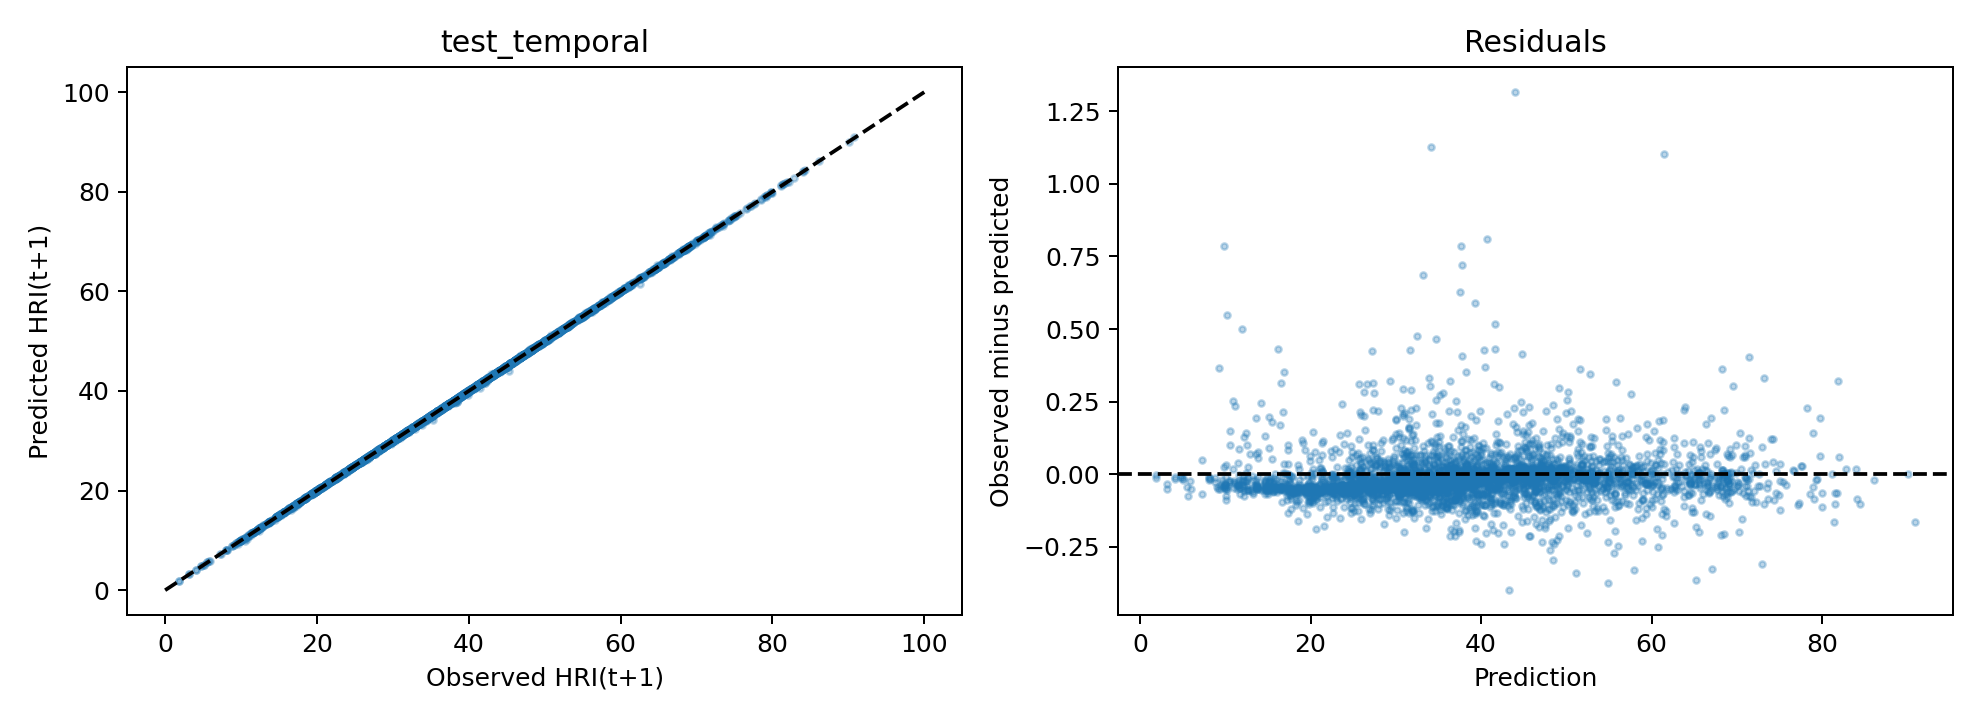

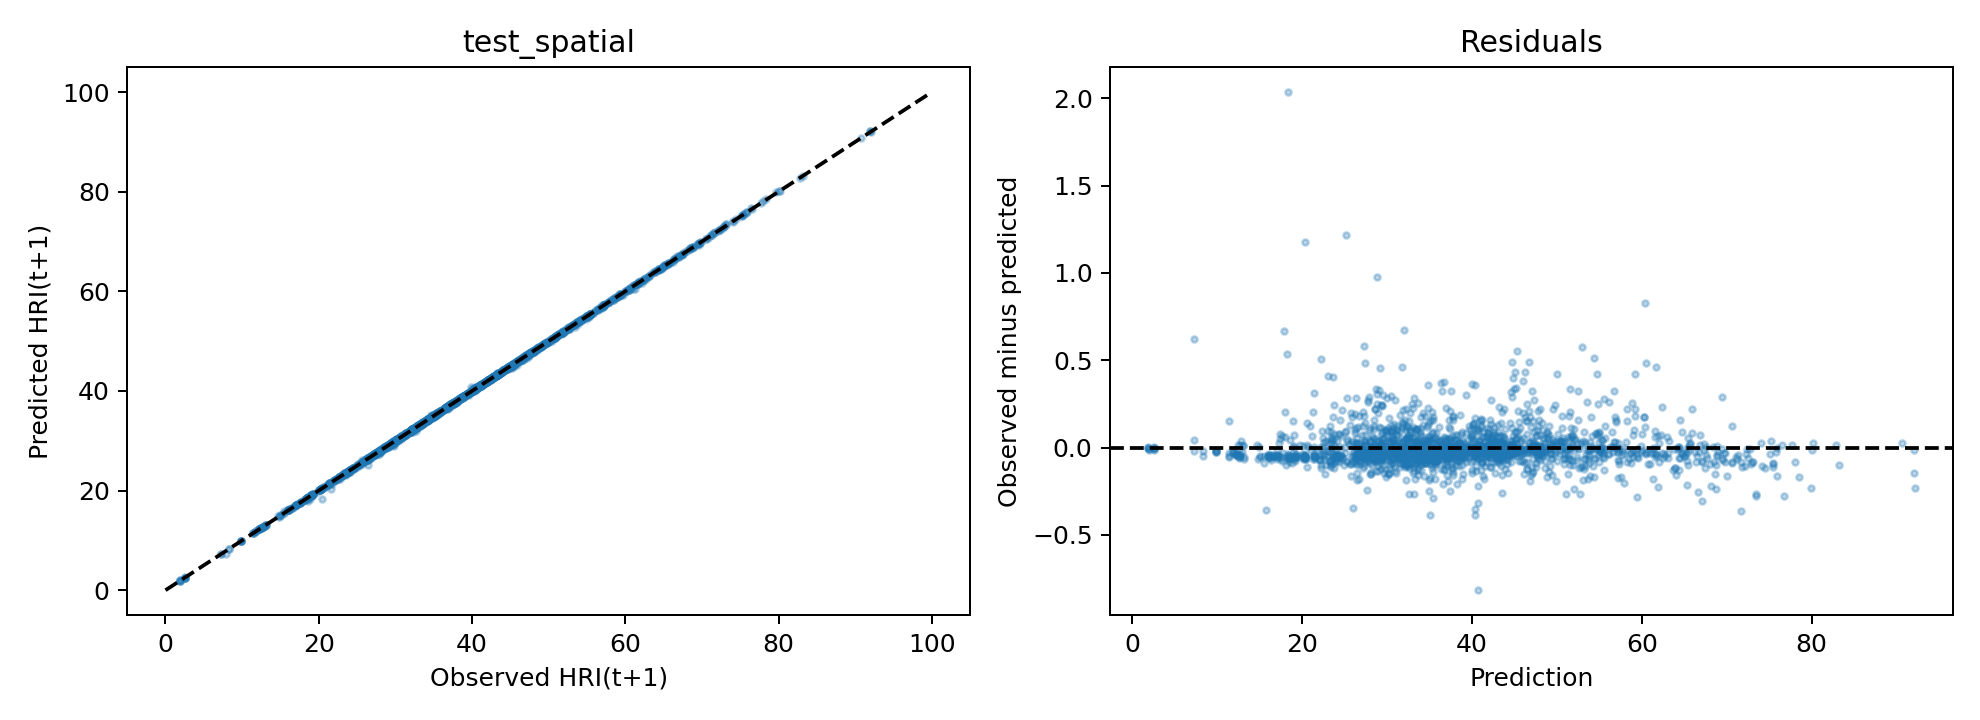

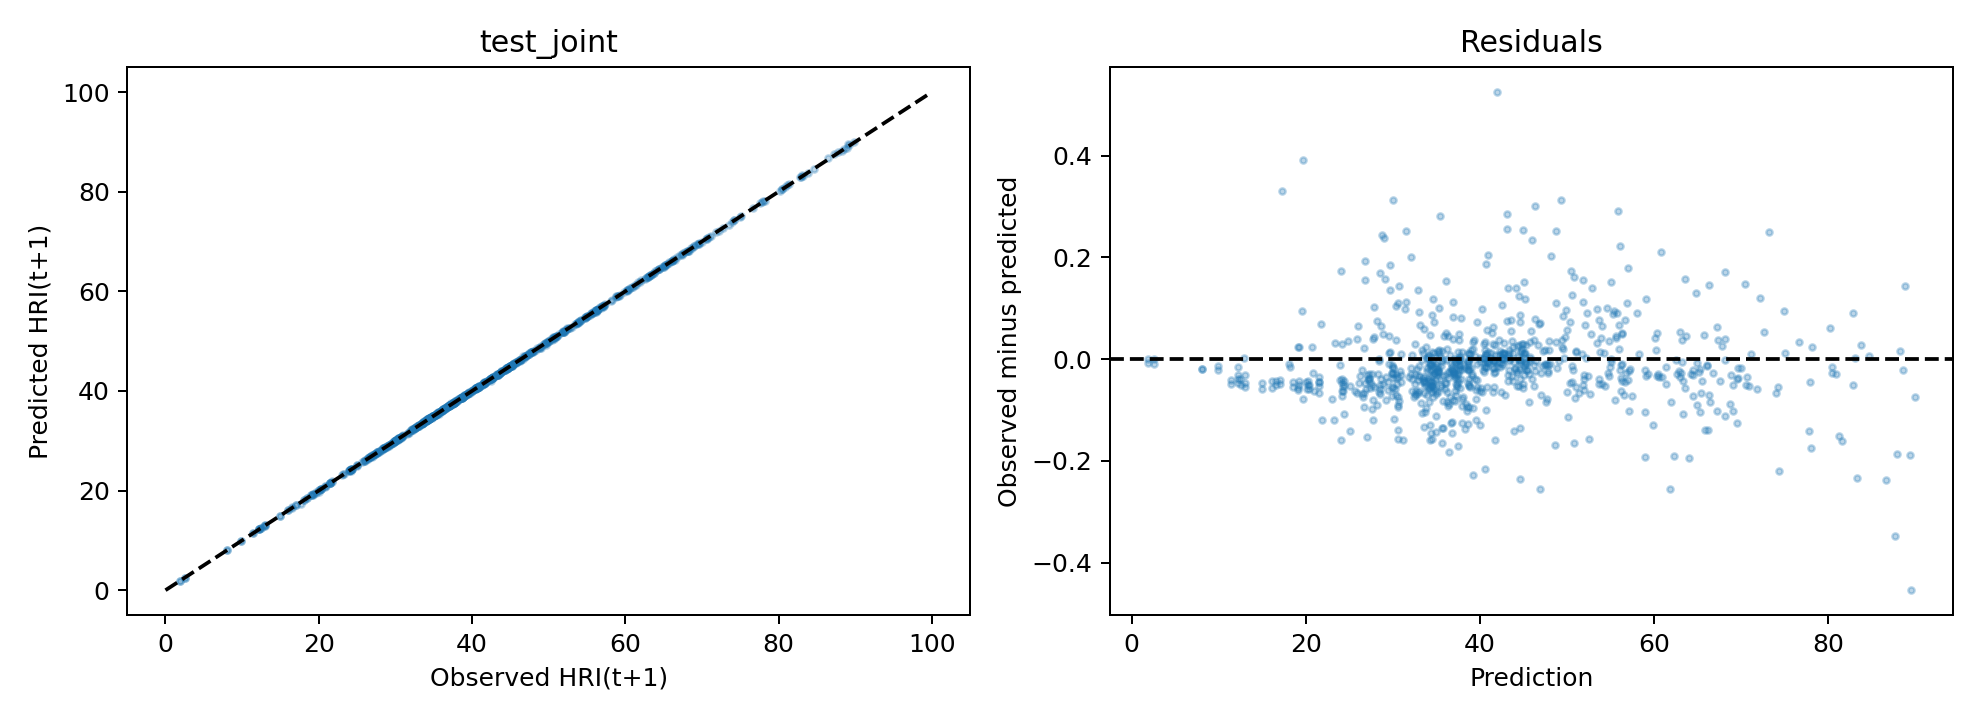

In [14]:
for view in ['temporal', 'spatial', 'joint']:
    image_path = ARTIFACTS / f'final_test/test_{view}_diagnostics.png'
    if image_path.exists():
        display(Image(filename=str(image_path)))
